# 04: Results Analysis and Investor Application

Uses the frozen **test-set** predictions from notebook 03 (6,094 homes). Main model: the **neural network** (best R² on test). Linear regression is shown alongside where the comparison is useful.

1. **Where is the model wrong?** By price range, city, market segment (K-means) and status, plus the worst misses.
2. **Why is dollar RMSE twice the MAE?** How errors concentrate in expensive homes.
3. **Investor application:** screening for-sale homes listed below predicted value, and why that needs care.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.lines import Line2D

sys.path.insert(0, str(Path.cwd().parent / "src"))
import preprocess as pp
from models import KMeans
from plot_style import apply_style, save, BLUE, ORANGE, TEXT_2

apply_style()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
SEED = 42
dollars = mtick.FuncFormatter(lambda x, _: f"${x/1e6:.1f}M" if abs(x) >= 1e6 else f"${x/1e3:.0f}k")

t = pd.read_csv(pp.PROCESSED_DIR / "test_predictions.csv", dtype={"zip_code": "string"})
t["pred"] = t["pred_5"]          # neural network
t["pred_ols"] = t["pred_1"]      # linear regression
t["err_pct"] = (t.pred - t.price) / t.price * 100           # signed: + means over-predicted
t["abs_pct"] = t.err_pct.abs()
t["abs_dollar"] = (t.pred - t.price).abs()
t["abs_pct_ols"] = ((t.pred_ols - t.price) / t.price * 100).abs()
print(f"{len(t):,} test homes | median abs error {t.abs_pct.median():.1f}% | "
      f"median signed error {t.err_pct.median():+.1f}%")

def summarize(g):
    return pd.Series({"homes": len(g), "median price": g.price.median(),
                      "median % error": g.abs_pct.median(),
                      "median signed % error": g.err_pct.median(),
                      "within 20%": (g.abs_pct <= 20).mean() * 100,
                      "linear reg. median % error": g.abs_pct_ols.median()})

6,094 test homes | median abs error 15.1% | median signed error -0.6%


## 1. Error by price range

**Signed error** shows direction: +10% means the model guessed 10% too *high*. A good model's signed error should be near 0 in every range.

,homes,median price,median % error,median signed % error,within 20%,linear reg. median % error
band,,,,,,
< $150k,581.00,"120,000.00",34.37,32.06,31.67,38.16
$150–250k,"1,282.00","208,250.00",15.25,2.15,61.70,14.69
$250–400k,"2,136.00","325,000.00",11.79,-0.07,71.77,13.47
$400–700k,"1,480.00","499,000.00",14.57,-5.07,64.46,14.99
$700k–1.5M,492.00,"899,000.00",21.34,-13.26,46.75,20.75
> $1.5M,123.00,"2,000,000.00",33.36,-30.39,26.83,34.05


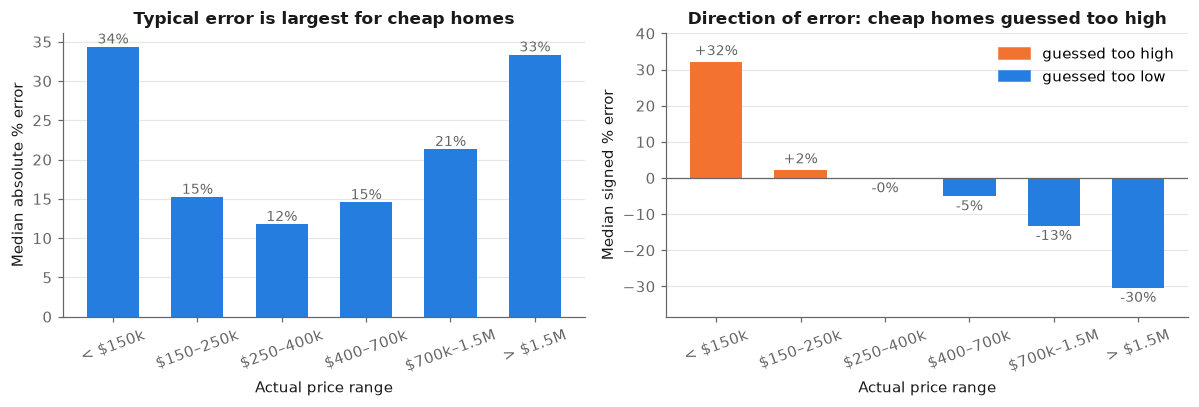

In [2]:
bands = [0, 150e3, 250e3, 400e3, 700e3, 1.5e6, np.inf]
labels = ["< $150k", "$150–250k", "$250–400k", "$400–700k", "$700k–1.5M", "> $1.5M"]
t["band"] = pd.cut(t.price, bands, labels=labels)
by_band = t.groupby("band", observed=True).apply(summarize, include_groups=False)
display(by_band)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.arange(len(by_band))
axes[0].bar(x, by_band["median % error"], color=BLUE, width=0.62)
for i, (v, n) in enumerate(zip(by_band["median % error"], by_band.homes)):
    axes[0].text(i, v + 0.4, f"{v:.0f}%", ha="center", fontsize=9, color=TEXT_2)
axes[0].set_title("Typical error is largest for cheap homes")
axes[0].set_ylabel("Median absolute % error")
s = by_band["median signed % error"]
axes[1].bar(x, s, color=[ORANGE if v > 0 else BLUE for v in s], width=0.62)
axes[1].axhline(0, color=TEXT_2, linewidth=0.8)
for i, v in enumerate(s):
    axes[1].text(i, v + (1 if v > 0 else -1), f"{v:+.0f}%", ha="center", va="bottom" if v > 0 else "top",
                 fontsize=9, color=TEXT_2)
axes[1].set_title("Direction of error: cheap homes guessed too high")
axes[1].set_ylabel("Median signed % error")
axes[1].set_ylim(s.min() - 8, s.max() + 8)
axes[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ORANGE), plt.Rectangle((0, 0), 1, 1, color=BLUE)],
               labels=["guessed too high", "guessed too low"], loc="upper right")
for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=20)
    ax.set_xlabel("Actual price range")
    ax.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "fig18_error_by_price")
plt.show()

This pattern is called **regression toward the mean**. When the features can't fully explain why a home is unusually cheap (needs repairs, a bad spot in the ZIP) or unusually expensive (a renovation, a view), the model's guess stays closer to a typical home.
Example: a $90k home in a $200/sqft ZIP probably has problems the data can't show, so the model prices it like an ordinary home there and guesses too high.

## 2. Where dollar errors come from

Dollar RMSE (~$194k) is about twice the dollar MAE (~$93k), because squaring makes a few huge misses dominate. How concentrated are they?

In [3]:
top = t.price >= t.price.quantile(0.95)
share = t.loc[top, "abs_dollar"].sum() / t.abs_dollar.sum()
sq_share = (t.loc[top, "abs_dollar"] ** 2).sum() / (t.abs_dollar ** 2).sum()
print(f"Most expensive 5% of homes (>= ${t.price.quantile(0.95):,.0f}):")
print(f"  {share:.0%} of total absolute dollar error, {sq_share:.0%} of total squared error (what RMSE uses)")
print(f"  median % error there: {t.loc[top, 'abs_pct'].median():.1f}% vs {t.loc[~top, 'abs_pct'].median():.1f}% for the rest")
print(f"Without the top 5%: MAE ${t.loc[~top, 'abs_dollar'].mean():,.0f}, "
      f"RMSE ${np.sqrt((t.loc[~top, 'abs_dollar'] ** 2).mean()):,.0f}")

Most expensive 5% of homes (>= $985,000):
  29% of total absolute dollar error, 71% of total squared error (what RMSE uses)
  median % error there: 29.3% vs 14.6% for the rest
Without the top 5%: MAE $69,510, RMSE $108,120


## 3. Error by city and status

In [4]:
top_cities = t.city.value_counts().head(10).index
by_city = (t[t.city.isin(top_cities)].groupby("city").apply(summarize, include_groups=False)
           .sort_values("median % error"))
display(by_city)
by_status = t.groupby("status").apply(summarize, include_groups=False)
display(by_status)

,homes,median price,median % error,median signed % error,within 20%,linear reg. median % error
city,,,,,,
New Bern,92.00,"267,000.00",11.02,5.09,68.48,11.36
Jacksonville,202.00,"211,500.00",12.73,-4.92,70.30,12.61
Wilmington,172.00,"401,155.00",13.26,2.16,63.37,15.38
Charlotte,930.00,"350,000.00",13.61,-4.12,67.96,14.92
Leland,97.00,"330,490.00",14.51,2.30,62.89,15.23
Greenville,99.00,"225,000.00",15.38,-8.34,57.58,16.54
Fayetteville,142.00,"182,700.00",16.42,-2.32,56.34,16.48
Asheville,83.00,"499,000.00",20.41,-5.04,48.19,18.89
Raleigh,93.00,"490,000.00",20.51,6.90,49.46,14.70


,homes,median price,median % error,median signed % error,within 20%,linear reg. median % error
status,,,,,,
for_sale,"3,623.00","349,900.00",15.99,0.13,58.43,16.31
sold,"2,471.00","300,000.00",13.85,-1.47,65.07,15.07


## 4. Market segments with K-means

Every ZIP gets 3 numbers, all from the **training** set: median log($/sqft), median log(house size) and median log(lot size).
K-means (the homework class, in `src/models.py`) groups ZIPs with similar profiles. Only ZIPs with at least 10 training homes are clustered, since tiny ZIPs give noisy medians. Test homes take their ZIP's segment; homes in other ZIPs are labeled "small ZIP".

**Choosing k with the elbow method:** inertia (total squared distance from each ZIP to its cluster center) always drops as k grows. We look for the "elbow" where adding another cluster stops helping much.

In [5]:
trn = pp.load_processed()["train"]
trn = trn.assign(lppsf=np.log(trn.price / trn.house_size), lsize=np.log(trn.house_size))
zips = trn.groupby("zip_code").agg(homes=("price", "size"), lppsf=("lppsf", "median"),
                                   lsize=("lsize", "median"), llot=("log_acre_lot", "median"))
zips = zips[zips.homes >= 10]
cols = ["lppsf", "lsize", "llot"]
zst = pp.Standardize().fit(zips[cols].values)
Z = zst.transform(zips[cols].values)
print(f"{len(zips)} ZIPs with 10+ training homes ({zips.homes.sum():,} of {len(trn):,} training homes)")

inertias = {k: KMeans(k, seed=SEED).fit(Z).inertia for k in range(1, 9)}
K = 4
km = KMeans(K, seed=SEED).fit(Z)
zips["cluster"] = km.predict(Z)

prof = zips.groupby("cluster").agg(ZIPs=("homes", "size"), homes=("homes", "sum"),
                                   ppsf=("lppsf", lambda s: np.exp(s.median())),
                                   sqft=("lsize", lambda s: np.exp(s.median())),
                                   acres=("llot", lambda s: np.expm1(s.median())))
# Name each cluster from its profile
names = {}
for c, r in prof.iterrows():
    if r.acres == prof.acres.max():
        names[c] = "Rural, big lots"
    elif r.ppsf == prof.ppsf.min():
        names[c] = "Affordable"
    elif r.sqft == prof.sqft.max():
        names[c] = "Upscale, large homes"
    else:
        names[c] = "Pricey, compact homes"
prof.index = [names[c] for c in prof.index]
display(prof.style.format({"ppsf": "${:,.0f}", "sqft": "{:,.0f}", "acres": "{:.2f}"}))

390 ZIPs with 10+ training homes (27,306 of 28,436 training homes)


,ZIPs,homes,ppsf,sqft,acres
"Upscale, large homes",108,7556,$198,"2,304",0.35
"Pricey, compact homes",101,10256,$221,"1,707",0.32
Affordable,125,8139,$136,"1,600",0.45
"Rural, big lots",56,1355,$187,"1,738",1.20


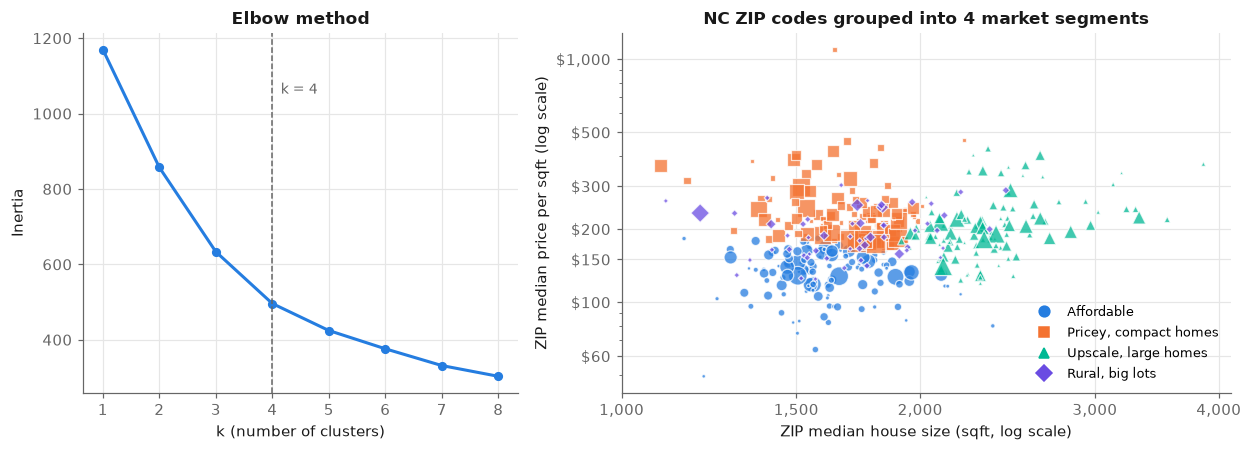

In [6]:
seg_colors = {"Affordable": "#257de0", "Pricey, compact homes": "#f47230",
              "Upscale, large homes": "#00b894", "Rural, big lots": "#6a4ce2"}
seg_markers = {"Affordable": "o", "Pricey, compact homes": "s", "Upscale, large homes": "^", "Rural, big lots": "D"}
zips["segment"] = zips.cluster.map(names)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].plot(list(inertias), list(inertias.values()), color=BLUE, linewidth=2, marker="o", markersize=5)
axes[0].axvline(K, color=TEXT_2, linestyle="--", linewidth=1)
axes[0].text(K + 0.15, max(inertias.values()) * 0.9, f"k = {K}", color=TEXT_2, fontsize=9)
axes[0].set_xlabel("k (number of clusters)")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow method")
for seg in seg_colors:
    s = zips[zips.segment == seg]
    axes[1].scatter(np.exp(s.lsize), np.exp(s.lppsf), s=np.clip(s.homes, 10, 300) * 0.5, alpha=0.75,
                    color=seg_colors[seg], marker=seg_markers[seg], edgecolors="white", linewidths=0.8, label=seg)
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${x:,.0f}"))
axes[1].xaxis.set_minor_formatter(mtick.NullFormatter()); axes[1].yaxis.set_minor_formatter(mtick.NullFormatter())
axes[1].set_xticks([1000, 1500, 2000, 3000, 4000])
axes[1].set_yticks([60, 100, 150, 200, 300, 500, 1000])
axes[1].set_xlabel("ZIP median house size (sqft, log scale)")
axes[1].set_ylabel("ZIP median price per sqft (log scale)")
axes[1].set_title("NC ZIP codes grouped into 4 market segments")
handles = [Line2D([], [], marker=seg_markers[s], color=seg_colors[s], linestyle="", markersize=7, label=s) for s in seg_colors]
axes[1].legend(handles=handles, loc="lower right", fontsize=8.5)
fig.tight_layout()
save(fig, "fig19_kmeans_segments")
plt.show()

In [7]:
t["segment"] = t.zip_code.map(zips.segment).fillna("Small ZIP (<10 training homes)")
by_seg = t.groupby("segment").apply(summarize, include_groups=False).sort_values("median % error")
display(by_seg)

,homes,median price,median % error,median signed % error,within 20%,linear reg. median % error
segment,,,,,,
"Upscale, large homes","1,561.00","420,000.00",13.01,-0.38,67.26,13.91
"Pricey, compact homes","2,203.00","369,000.00",15.33,-0.06,60.87,16.49
Affordable,"1,759.00","229,900.00",15.39,-3.09,60.32,15.48
"Rural, big lots",285.00,"315,000.00",21.29,2.65,48.77,22.45
Small ZIP (<10 training homes),286.00,"259,700.00",22.14,12.42,46.85,26.11


## 5. The worst misses

The 10 largest percentage errors. Do they look like model failures, or like data problems the model couldn't know about?

In [8]:
worst = t.nlargest(10, "abs_pct")[["price", "pred", "err_pct", "house_size", "bed", "bath", "status", "city", "zip_code"]]
worst.assign(price_per_sqft=worst.price / worst.house_size).style.format(
    {"price": "${:,.0f}", "pred": "${:,.0f}", "err_pct": "{:+.0f}%", "house_size": "{:,.0f}", "price_per_sqft": "${:,.0f}",
     "bed": "{:.0f}", "bath": "{:.0f}"})

,price,pred,err_pct,house_size,bed,bath,status,city,zip_code,price_per_sqft
15,"$15,950","$228,077",+1330%,"1,800",3,2,sold,Henderson,27536,$9
2370,"$69,000","$892,635",+1194%,"2,314",4,3,for_sale,Nags Head,27959,$30
3321,"$15,000","$131,819",+779%,"1,404",3,1,for_sale,Murfreesboro,27855,$11
2923,"$52,790","$455,402",+763%,"1,924",3,2,for_sale,Durham,27703,$27
1876,"$65,000","$522,336",+704%,"3,708",8,5,for_sale,Enfield,27823,$18
2342,"$34,900","$206,151",+491%,"1,525",3,2,for_sale,Richlands,28574,$23
1974,"$47,000","$265,841",+466%,"1,450",3,2,for_sale,Orrum,28369,$32
230,"$40,000","$219,239",+448%,"1,350",3,1,for_sale,Carthage,28327,$30
1123,"$25,000","$136,919",+448%,"1,067",3,1,for_sale,Grimesland,27837,$23
2665,"$30,000","$147,565",+392%,"1,100",3,1,sold,Statesville,28677,$27


## 6. Investor application: screening for-sale listings

**Idea:** for a home that's **for sale**, compare its asking price with what the model predicts for a home like it.
If the asking price is well below the prediction, the home *might* be underpriced, which is worth a closer look as a rental purchase.

value ratio = predicted price / asking price
- ratio 1.0: priced like similar homes
- ratio 1.25: model says similar homes go for 25% more

Section 1's lesson matters here: cheap homes are systematically over-predicted. A naive screen would mostly flag cheap homes that are cheap for reasons the data can't see (condition, location within the ZIP). So we compare each home's ratio with the **typical ratio in its price range**, which removes the known bias.

3,623 for-sale test homes
Naive screen (prediction >= 1.25 x asking): 681 homes flagged
Bias-adjusted screen (>= 1.25 x the typical ratio for its price range): 639 homes flagged


,naive flags,adjusted flags,all for-sale homes
band,,,
< $150k,195,98,339
$150–250k,147,123,645
$250–400k,172,145,1210
$400–700k,117,153,963
$700k–1.5M,44,86,367
> $1.5M,6,34,99


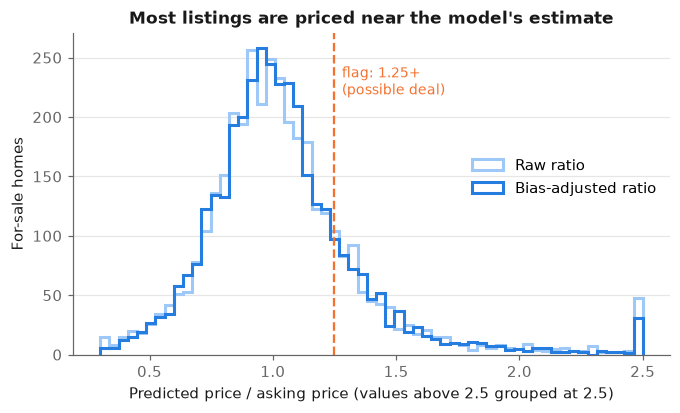

In [9]:
fs = t[t.status == "for_sale"].copy()
fs["ratio"] = fs.pred / fs.price
fs["band_typical_ratio"] = fs.groupby("band", observed=True).ratio.transform("median")
fs["adj_ratio"] = fs.ratio / fs.band_typical_ratio

naive = fs.ratio >= 1.25
adjusted = fs.adj_ratio >= 1.25
print(f"{len(fs):,} for-sale test homes")
print(f"Naive screen (prediction >= 1.25 x asking): {naive.sum()} homes flagged")
print(f"Bias-adjusted screen (>= 1.25 x the typical ratio for its price range): {adjusted.sum()} homes flagged")
display(pd.DataFrame({"naive flags": fs[naive].band.value_counts(sort=False),
                      "adjusted flags": fs[adjusted].band.value_counts(sort=False),
                      "all for-sale homes": fs.band.value_counts(sort=False)}))

fig, ax = plt.subplots(figsize=(7, 3.8))
bins = np.linspace(0.3, 2.5, 60)
ax.hist(fs.ratio.clip(0.3, 2.5), bins=bins, histtype="step", linewidth=2, color="#9dc8f7", label="Raw ratio")
ax.hist(fs.adj_ratio.clip(0.3, 2.5), bins=bins, histtype="step", linewidth=2, color=BLUE, label="Bias-adjusted ratio")
ax.axvline(1.25, color=ORANGE, linestyle="--", linewidth=1.5)
ax.text(1.28, ax.get_ylim()[1] * 0.9, "flag: 1.25+\n(possible deal)", color=ORANGE, fontsize=9, va="top")
ax.set_xlabel("Predicted price / asking price (values above 2.5 grouped at 2.5)")
ax.set_ylabel("For-sale homes")
ax.set_title("Most listings are priced near the model's estimate")
ax.legend(loc="center right", bbox_to_anchor=(1.0, 0.55))
ax.grid(axis="x", visible=False)
save(fig, "fig20_value_ratio")
plt.show()

In [10]:
# Very large ratios are more likely data problems than bargains (see the worst misses above)
fs["ppsf"] = fs.price / fs.house_size
extreme = adjusted & (fs.adj_ratio >= 1.6)
plausible = adjusted & (fs.adj_ratio < 1.6)
print(f"Flagged homes with ratio >= 1.6 (likely data issues or major condition problems): {extreme.sum()}")
print(f"  median asking $/sqft {fs[extreme].ppsf.median():.0f} vs {fs.ppsf.median():.0f} for all for-sale homes")
print(f"Flagged homes with ratio 1.25-1.6 (plausible 'worth a look'): {plausible.sum()}")
print(f"All test homes under $40/sqft: {(t.price / t.house_size < 40).sum()} "
      f"(median error there {t[t.price / t.house_size < 40].abs_pct.median():.0f}%)")

# Worked example: plausible flags priced $150k-$400k (a realistic first-rental budget)
budget = fs[plausible & fs.price.between(150e3, 400e3)].sort_values("adj_ratio", ascending=False)
print(f"\n{len(budget)} plausible flagged homes priced $150k-$400k")
budget[["price", "pred", "ratio", "adj_ratio", "ppsf", "house_size", "bed", "bath", "city", "zip_code"]].head(8).style.format(
    {"price": "${:,.0f}", "pred": "${:,.0f}", "ratio": "{:.2f}", "adj_ratio": "{:.2f}", "ppsf": "${:,.0f}",
     "house_size": "{:,.0f}", "bed": "{:.0f}", "bath": "{:.0f}"})

Flagged homes with ratio >= 1.6 (likely data issues or major condition problems): 170
  median asking $/sqft 107 vs 185 for all for-sale homes
Flagged homes with ratio 1.25-1.6 (plausible 'worth a look'): 469
All test homes under $40/sqft: 38 (median error there 245%)

210 plausible flagged homes priced $150k-$400k


,price,pred,ratio,adj_ratio,ppsf,house_size,bed,bath,city,zip_code
2117,"$349,900","$569,729",1.63,1.60,$113,"3,100",4,4,Gates,27937
1032,"$369,500","$601,339",1.63,1.60,$148,"2,492",3,3,Morehead City,28557
5182,"$225,000","$369,064",1.64,1.59,$161,"1,400",3,2,Robbinsville,28771
962,"$360,000","$582,299",1.62,1.59,$144,"2,500",3,2,Pinehurst,28374
1791,"$159,000","$259,570",1.63,1.59,$139,"1,143",2,2,Brevard,28712
996,"$299,900","$484,366",1.62,1.58,$104,"2,884",4,4,Wallace,28466
5231,"$224,500","$362,216",1.61,1.57,$75,"2,975",4,3,Goldsboro,27530
1483,"$328,975","$523,006",1.59,1.56,$196,"1,680",4,4,Charlotte,28216


**How to use this (and what not to do):**
- **Very high ratios (1.6+) are usually not bargains.** They tend to be data problems (auctions, partial-interest sales, typos) or homes needing major work, as the worst-misses table shows.
- It's a **shortlist generator**, not a buy signal. With a typical error of about 15%, a ratio of 1.25 is only somewhat beyond normal model noise.
- Every flagged home needs the checks the model can't do: photos and condition, exact street, HOA fees, taxes, and recent comparable sales.
- The data is from 2021–2022, so the dollar values are out of date. The *method* carries over to current listings.
- For a rental decision, combine the price with a rent estimate (e.g. the 1% rule: monthly rent ≈ 1% of price) from current local rental listings.

## 7. Summary

**Where the model is wrong**
1. **Regression toward the mean** (Fig 18): homes under $150k are guessed **+32% too high** and homes over $1.5M **-30% too low**. In the $250–400k middle, the median error is just **11.8%** with no bias. The model is most reliable where most homes are.
2. **Dollar errors concentrate in luxury homes:** the most expensive 5% (≥ $985k) cause 29% of all absolute dollar error and **71% of squared error**. Without them, MAE drops from $93k to **$70k** and RMSE from $194k to **$108k**.
3. **By city:** best in New Bern (11.0%), Jacksonville (12.7%), Wilmington (13.3%) and Charlotte (13.6%); worst in Asheville, Raleigh and Durham (~20.5%), the more varied, pricier markets.
4. **Sold homes are easier** (13.9%) than for-sale listings (16.0%). Asking prices are noisier than real sale prices.
5. **K-means segments** (k = 4 by the elbow method, Fig 19): upscale/large-home ZIPs are the most predictable (13.0%), and rural big-lot ZIPs (21.3%) and small ZIPs with fewer than 10 training homes (22.1%, guessed +12% too high) the least. Less data per area means worse location information.
6. **Worst misses are data problems:** every top-10 miss is priced at **$9–$32/sqft** (typical: about $185). These are probably auctions, partial-interest sales, typos or distressed homes. The 38 test homes under $40/sqft have a median error of 245%.

**Investor screen** (for-sale homes, Fig 20)
- Most listings sit near the model's estimate (ratio about 1.0).
- A bias-adjusted screen (prediction ≥ 1.25× the typical ratio for the home's price range) flags 639 of 3,623 listings. 170 of those have ratios ≥ 1.6 and a median of $107/sqft (vs. $185), mostly data issues or condition problems. **469 are in the plausible 1.25–1.6 range**, 210 of them priced $150k–$400k.
- This is a shortlist for further research, not a buy signal (typical error is about 15%).

**Improvements suggested by the analysis**
1. **Filter non-market sales:** drop listings below about $40/sqft (or flag them) during preprocessing.
2. **More information per home:** year built, condition, exact coordinates (NC OneMap parcels), school ratings. The ~15% error floor across all models suggests missing features, not a weak algorithm.
3. **Treat the price extremes separately:** a dedicated luxury model, or sample weights, to reduce regression toward the mean.
4. **Prediction ranges, not single numbers:** e.g. "$280k–$340k", so an investor knows how uncertain each estimate is.
5. **Update the data:** 2021–2022 prices are dated. Retrain on current listings, or adjust with a price index.